## 1. Import thư viện và nạp dữ liệu vào notebook

In [38]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
# Đọc file Excel
Online_Retail_data = pd.read_excel("data/Online-Retail.xlsx")

In [39]:
Online_Retail_data.head(5)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [40]:
print(Online_Retail_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB
None


In [41]:
Online_Retail_data.dtypes


InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

In [42]:
Online_Retail_data.shape

(541909, 8)

In [43]:
num_duplicates = Online_Retail_data.duplicated().sum()
print(f"Số dòng bị trùng lặp: {num_duplicates}")

Số dòng bị trùng lặp: 5268


In [44]:
Online_Retail_data_duplicate = Online_Retail_data.drop_duplicates()


In [45]:
num_duplicates = Online_Retail_data_duplicate.duplicated().sum()
print(f"Số dòng bị trùng lặp: {num_duplicates}")

Số dòng bị trùng lặp: 0


In [46]:
Online_Retail_data_duplicate.isnull().sum()


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [48]:
# 1. Loại bỏ các dòng thiếu CustomerID
df_clean = Online_Retail_data_duplicate.dropna(subset=['CustomerID']).copy()

# 2. Ép kiểu CustomerID về số nguyên (int)
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# 3. Lọc bỏ các đơn hàng bị hủy hoặc lỗi kho (Quantity <= 0 hoặc UnitPrice <= 0)
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# 4. Chuyển InvoiceDate sang kiểu datetime (nếu chưa phải)
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# 5. Tạo cột Tổng tiền (TotalPrice) cho mỗi dòng
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']

# Kiểm tra lại thông tin dataset sau khi làm sạch
print("--- THÔNG TIN DATASET SẠCH ---")
print(f"Số dòng còn lại: {len(df_clean):,}")
print("Số lượng NULL ở các cột:")
print(df_clean.isnull().sum())
df_clean.head()

--- THÔNG TIN DATASET SẠCH ---
Số dòng còn lại: 392,692
Số lượng NULL ở các cột:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [49]:
# Khai báo danh sách các cột số cần tính toán
cols = ['Quantity', 'UnitPrice', 'TotalPrice']

for col in cols:
    data = df_clean[col]

    # Tính toán từng chỉ số
    data_mean = data.mean()
    data_median = data.median()
    data_mode = stats.mode(data, keepdims=True)
    data_variance = data.var()
    data_sd = data.std()
    data_min = data.min()
    data_max = data.max()
    data_percentile = np.percentile(data, 60)
    data_q1 = np.percentile(data, 25)
    data_q3 = np.percentile(data, 75)
    data_IQR = data_q3 - data_q1

    # In kết quả theo mẫu
    print(f"================ CỘT: {col} ================")
    print(f"Mean: {data_mean:.2f}")
    print(f"Median: {data_median:.2f}")
    print(f"Mode: {np.ravel(data_mode.mode)[0]}")
    print(f"Variance: {data_variance:.2f}")
    print(f"Standard Deviation: {data_sd:.2f}")
    print(f"Min: {data_min} | Max: {data_max}")
    print(f"Range: {data_max - data_min:.2f}")
    print(f"60th Percentile: {data_percentile:.2f}")
    print(f"Q3 (75th Percentile): {data_q3:.2f}")
    print(f"IQR: {data_IQR:.2f}")
    print("-" * 45 + "\n")

================ CỘT: Quantity ================
Mean: 13.12
Median: 6.00
Mode: 1
Variance: 32577.66
Standard Deviation: 180.49
Min: 1 | Max: 80995
Range: 80994.00
60th Percentile: 8.00
Q3 (75th Percentile): 12.00
IQR: 10.00
---------------------------------------------

================ CỘT: UnitPrice ================
Mean: 3.13
Median: 1.95
Mode: 1.25
Variance: 494.70
Standard Deviation: 22.24
Min: 0.001 | Max: 8142.75
Range: 8142.75
60th Percentile: 2.10
Q3 (75th Percentile): 3.75
IQR: 2.50
---------------------------------------------

================ CỘT: TotalPrice ================
Mean: 22.63
Median: 12.45
Mode: 15.0
Variance: 96782.73
Standard Deviation: 311.10
Min: 0.001 | Max: 168469.6
Range: 168469.60
60th Percentile: 15.00
Q3 (75th Percentile): 19.80
IQR: 14.85
---------------------------------------------



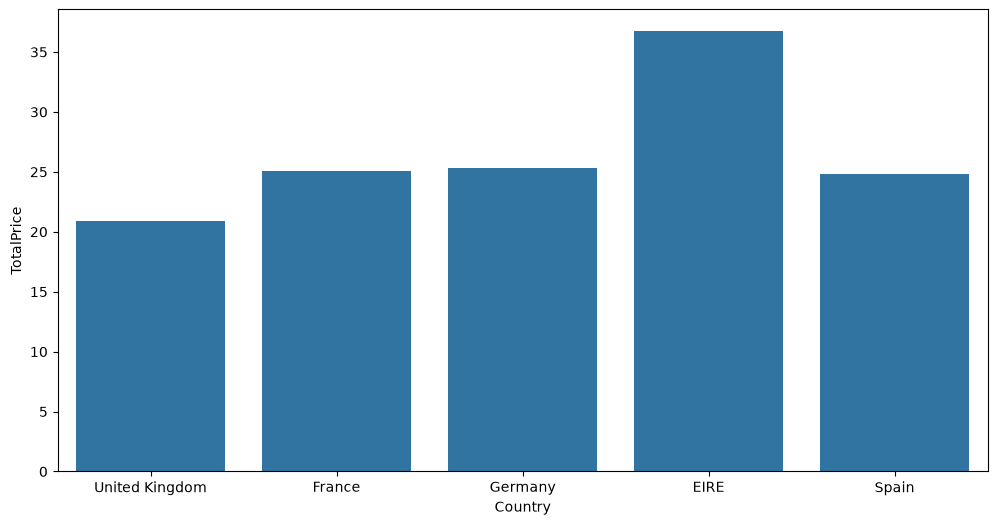

C:\Users\BAO\AppData\Local\Temp\ipykernel_28644\24410971.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


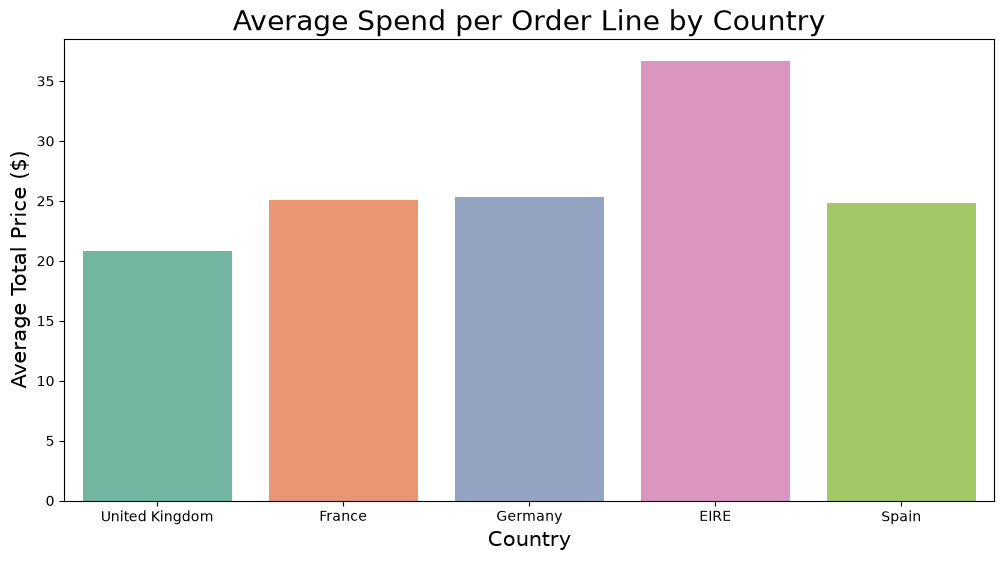

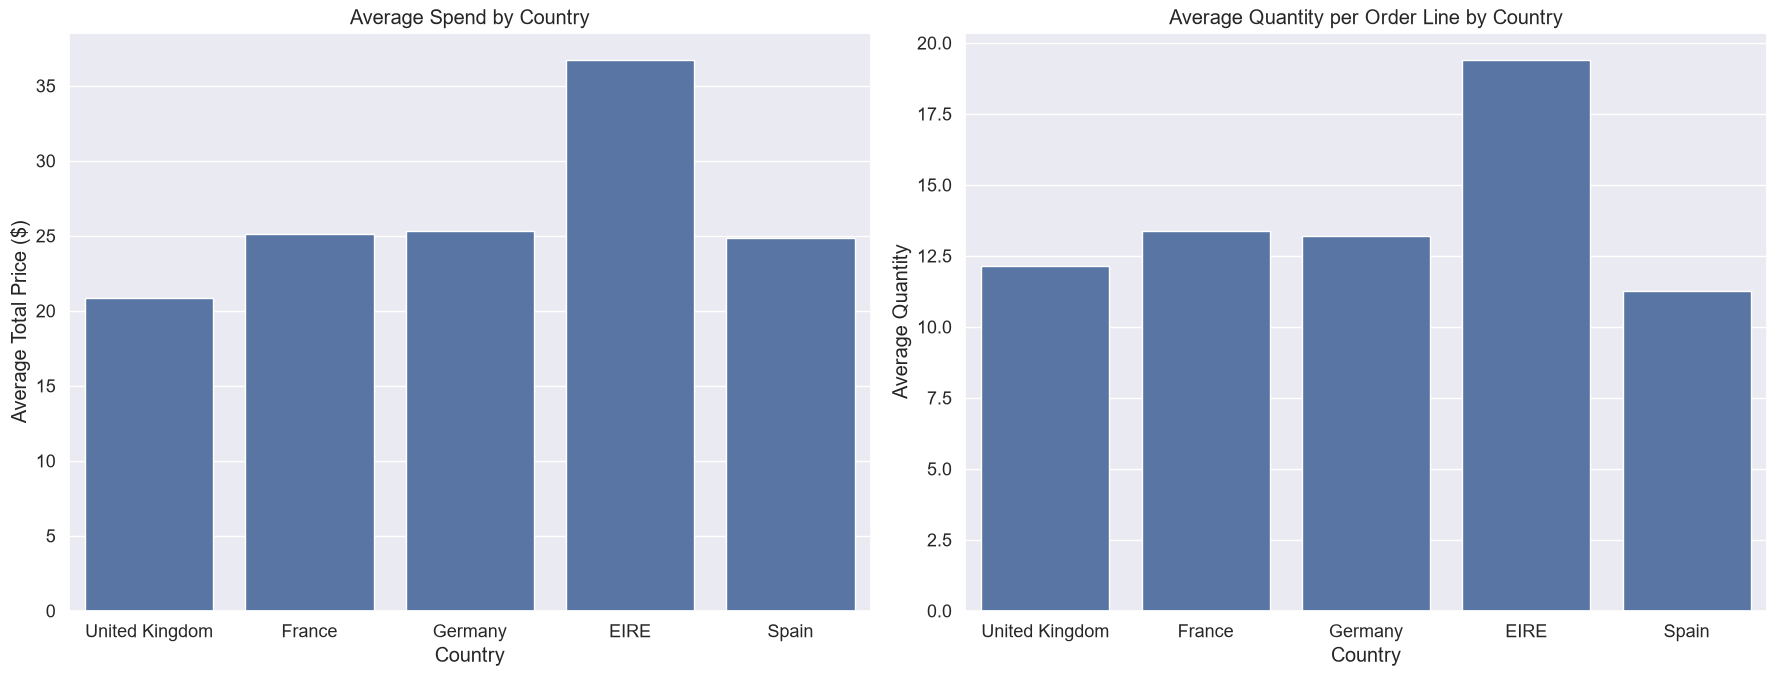

In [54]:
# Lấy Top 5 quốc gia có số lượng giao dịch nhiều nhất để vẽ biểu đồ cho rõ ràng
top5_countries = df_clean['Country'].value_counts().head(5).index
data = df_clean[df_clean['Country'].isin(top5_countries)]

# --- Case 1: Basic ---
plt.figure(figsize=(12, 6))
sns.barplot(data=data, x="Country", y="TotalPrice", errorbar=None)
plt.show()

# --- Case 2: Advanced 1 ---
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=data, x="Country", y="TotalPrice", palette="Set2", errorbar=None
)
ax.set_xlabel("Country", fontsize=15)
ax.set_ylabel("Average Total Price ($)", fontsize=15)
ax.set_title("Average Spend per Order Line by Country", fontsize=20)
plt.show()

# --- Case 3: View multiple perspectives at once ---
sns.set_theme(font_scale=1.2)

fig, ax = plt.subplots(1, 2, figsize=(18, 7))

# Biểu đồ 1: Total Price
ax1 = sns.barplot(
    data=data, x="Country", y="TotalPrice", ax=ax[0], errorbar=None
)
ax1.set_xlabel("Country")
ax1.set_ylabel("Average Total Price ($)")
ax1.set_title("Average Spend by Country")

# Biểu đồ 2: Quantity
ax2 = sns.barplot(
    data=data, x="Country", y="Quantity", ax=ax[1], errorbar=None
)
ax2.set_xlabel("Country")
ax2.set_ylabel("Average Quantity")
ax2.set_title("Average Quantity per Order Line by Country")

plt.tight_layout()
plt.show()

# Reset lại theme
sns.reset_orig()